In [1]:
from pathlib import Path
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    current = start.resolve()
    while current != current.parent:
        if (current / "src").exists():
            return current
        current = current.parent
    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())
os.chdir(PROJECT_ROOT)

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CWD:", Path.cwd())
print("ARTIFACTS:", ARTIFACTS)

PROJECT_ROOT: .
CWD: .
ARTIFACTS: ./artifacts


In [2]:
from ips_learning.visualization.utils import FigureRepository, TableRepository
figure_repo = FigureRepository(root_dir=ARTIFACTS)
table_repo = TableRepository(root_dir=ARTIFACTS)

In [3]:
SYSTEM_NAME = "spp"
PROFILE_NAME = "spp_velocity_grid_clumps"
SYSTEM_ORDER = 2
INTERACTION_TYPE = "energy"
ENVIRONMENT_VARIABLE = "velocity"

# Stage 2.2b: Support and density diagnostics

In [4]:

TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

KDE_SPLIT = "kde"
KDE_DATASET_NAME = "dataset_kde"

FIGURE_STAGE = "step_2_2b"

In [5]:
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.features.feature_repository import FeatureRepository
from ips_learning.bases.repository import BasisRepository

from ips_learning.statistics.density import build_empirical_error_density


from ips_learning.statistics.density_repository import DensityRepository
from ips_learning.visualization.data_support import DataSupportVisualizer

In [6]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")
feature_repo = FeatureRepository(root_dir=ARTIFACTS / "features")
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")
density_repo = DensityRepository(root=ARTIFACTS / "densities")

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

features = feature_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    feature_name=TRAIN_FIT_DATASET_NAME,
)

basis_bundle = basis_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    basis_name=TRAIN_FIT_DATASET_NAME,
)

kernel_density_ref, env_density_ref = density_repo.load(
    system_name=SYSTEM_NAME,
    split=KDE_SPLIT,
    name=KDE_DATASET_NAME,
)

print("Loaded dataset/features/basis.")
print("X:", train_fit_dataset.X.shape)
print("V:", None if train_fit_dataset.V is None else train_fit_dataset.V.shape)
print("R:", features.R.shape)
print("Basis localization:", basis_bundle.localization_metadata)

Loaded dataset/features/basis.
X: (50, 101, 10, 2)
V: (50, 101, 10, 2)
R: (50, 51, 10, 10, 1)
Basis localization: {'alignment_basis_source': 'radial_basis', 'basis_stage': '2.2', 'energy_basis_source': 'radial_basis', 'env_max': [2.8284271247461903, 2.8284271247461903], 'env_min': [-2.8284271247461903, -2.8284271247461903], 'environment_degree': 1, 'environment_family': 'bspline', 'environment_knots': [[-2.8284271247461903, -2.8284271247461903, -2.199887763691481, -1.5713484026367723, -0.9428090415820634, -0.3142696805273544, 0.3142696805273544, 0.9428090415820636, 1.5713484026367728, 2.1998877636914815, 2.8284271247461903, 2.8284271247461903], [-2.8284271247461903, -2.8284271247461903, -2.199887763691481, -1.5713484026367723, -0.9428090415820634, -0.3142696805273544, 0.3142696805273544, 0.9428090415820636, 1.5713484026367728, 2.1998877636914815, 2.8284271247461903, 2.8284271247461903]], 'environment_variable': 'velocity', 'interaction_type': 'energy', 'n_alignment_basis': 10, 'n_energ

In [ ]:
# Canonical empirical training density and evaluation grids.
#
# The M_rho=2000 reference KDE remains separate; both reference
# and empirical densities are evaluated on these same grids.
empirical_density = build_empirical_error_density(
    features=features,
    localization_metadata=basis_bundle.localization_metadata,
)

r_grid = empirical_density.r_grid
z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid

train_density = empirical_density.kernel_weights

if z2_grid is None:
    train_density_grid = empirical_density.environment_weights
else:
    train_density_grid = empirical_density.environment_weights.reshape(
        len(z1_grid),
        len(z2_grid),
    )


In [ ]:
# Pairwise-distance support:
# evaluate the M_rho=2000 reference KDE on the same canonical grid
# used for the empirical training density.
reference_pdf = kernel_density_ref.evaluate(r_grid)

viz = DataSupportVisualizer()

fig = viz.plot_pairwise_distance_support(
    basis_bundle=basis_bundle,
    r_grid=r_grid,
    reference_pdf=reference_pdf,
    train_density=train_density,
    title=None,
    reference_label=rf"$\rho_R$",
    train_label=rf"$\hat{{\rho}}_R$",
    xlabel=r"$r$",
    ylabel=rf"$\rho_R$",
)


In [9]:
figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "pairwise_distance_support.png"
pdf_path = figure_dir / "pairwise_distance_support.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
./artifacts/spp/figures/step_2_2b/pairwise_distance_support.png
./artifacts/spp/figures/step_2_2b/pairwise_distance_support.pdf


In [ ]:
# Environment support metadata.
loc = basis_bundle.localization_metadata

env_min = np.asarray(
    loc.get("env_min", loc.get("v_min")),
    dtype=float,
)
env_max = np.asarray(
    loc.get("env_max", loc.get("v_max")),
    dtype=float,
)

environment_variable = loc.get(
    "environment_variable",
    "position" if SYSTEM_ORDER == 1 else "velocity",
)

print("environment_variable:", environment_variable)
print("env_min:", env_min)
print("env_max:", env_max)
print("z1_grid:", z1_grid.shape)
print("z2_grid:", None if z2_grid is None else z2_grid.shape)


In [ ]:
# Evaluate the M_rho=2000 reference environment KDE on the same
# canonical grid used for the empirical training density.
if z2_grid is None:
    density_grid = env_density_ref.evaluate(z1_grid)
else:
    density_grid = env_density_ref.evaluate_on_grid(
        z1_grid,
        z2_grid,
    )


In [ ]:
# The empirical training environment density was built directly
# from the current training features in cell 7.
#
# density_grid       -> M_rho=2000 reference KDE
# train_density_grid -> empirical training measure


Saved:
./artifacts/spp/figures/step_2_2b/environment_support_density.png
./artifacts/spp/figures/step_2_2b/environment_support_density.pdf


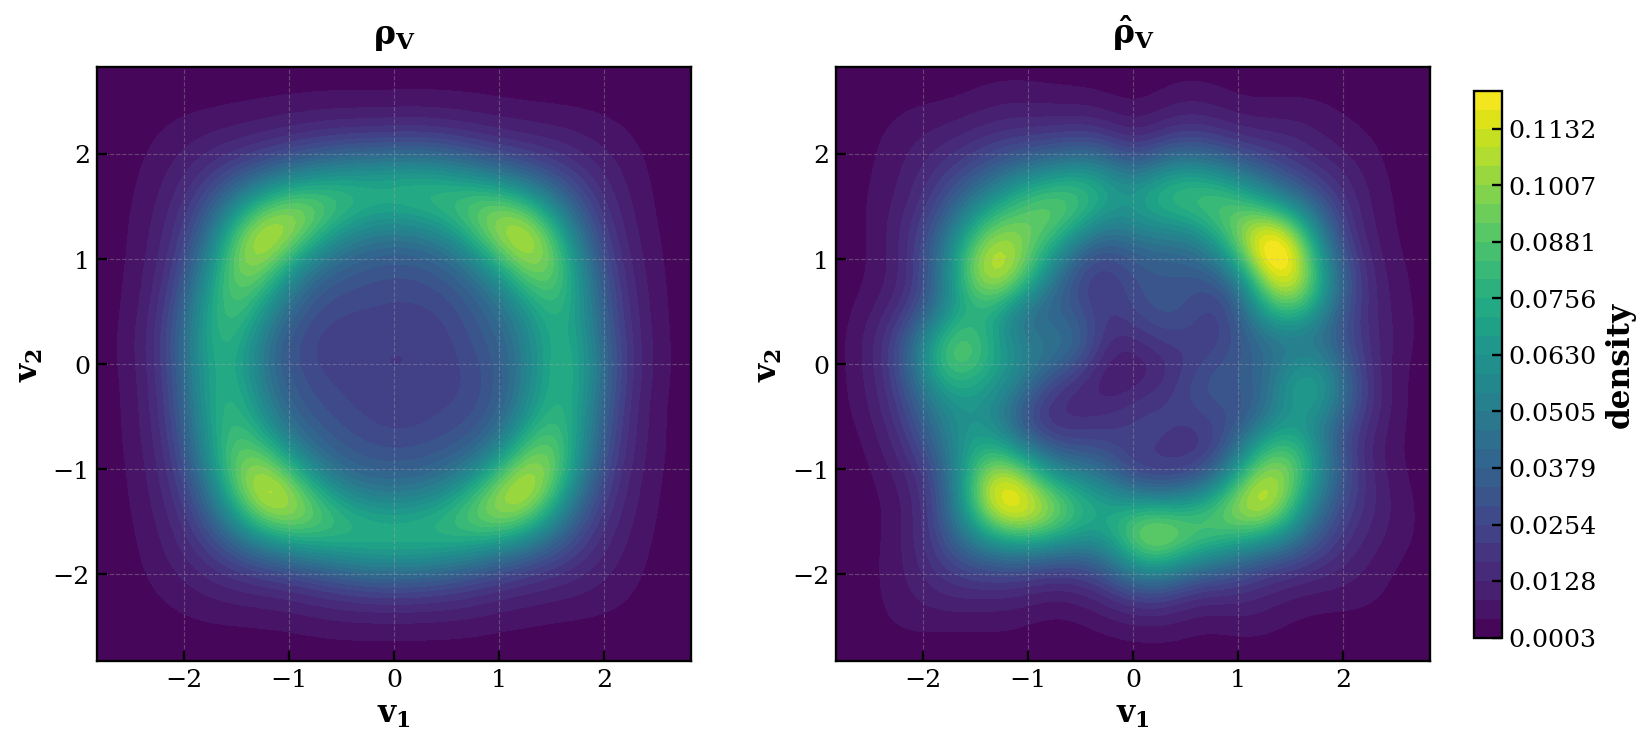

In [13]:
fig_env = viz.plot_environment_support_density(
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    density_grid=density_grid,
    empirical_density_grid =train_density_grid,
    title=None,
    density_label=rf"$\rho_V$",
    empirical_density_label=rf"$\hat{{\rho}}_V$",
    z_label=r"$v$",#r"$x$" if SYSTEM_ORDER == 1 else r"$v$",
    ylabel = rf"$\rho_V$",
)

figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "environment_support_density.png"
pdf_path = figure_dir / "environment_support_density.pdf"

fig_env.savefig(png_path, dpi=300, bbox_inches="tight")
fig_env.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

# two plots: one true and one empirical data

In [14]:
# Basis localization summary table
loc = basis_bundle.localization_metadata

env_min = np.asarray(loc.get("env_min", loc.get("v_min")), dtype=float)
env_max = np.asarray(loc.get("env_max", loc.get("v_max")), dtype=float)

row = {
    "system_name": SYSTEM_NAME,
    "profile_name": PROFILE_NAME,
    "dataset_name": TRAIN_FIT_DATASET_NAME,
    "system_order": SYSTEM_ORDER,
    "environment_variable": loc.get("environment_variable", ENVIRONMENT_VARIABLE),

    "radial_family": loc["radial_family"],
    "radial_degree": loc["radial_degree"],
    "n_radial_basis": basis_bundle.radial_basis.n_basis,

    "environment_family": loc.get("environment_family", loc.get("velocity_family")),
    "environment_degree": loc.get("environment_degree", loc.get("velocity_degree")),
    "environment_n_basis_per_dim": basis_bundle.environment_basis.n_basis_per_dim,

    "r_min": float(loc["r_min"]),
    "r_max": float(loc["r_max"]),
}

for d in range(env_min.shape[0]):
    row[f"z{d+1}_min"] = float(env_min[d])
    row[f"z{d+1}_max"] = float(env_max[d])

basis_localization_summary = pd.DataFrame([row])
basis_localization_summary

table_dir = table_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
table_dir.mkdir(parents=True, exist_ok=True)

csv_path = table_dir / "basis_localization_summary.csv"
tex_path = table_dir / "basis_localization_summary.tex"

basis_localization_summary.to_csv(csv_path, index=False)
basis_localization_summary.to_latex(
    tex_path,
    index=False,
    float_format="%.4e",
)

print("Saved:")
print(csv_path)
print(tex_path)

Saved:
./artifacts/spp/tables/step_2_2b/basis_localization_summary.csv
./artifacts/spp/tables/step_2_2b/basis_localization_summary.tex


In [15]:
basis_localization_summary

,system_name,profile_name,dataset_name,system_order,environment_variable,radial_family,radial_degree,n_radial_basis,environment_family,environment_degree,environment_n_basis_per_dim,r_min,r_max,z1_min,z1_max,z2_min,z2_max
0,spp,spp_velocity_grid_clumps,dataset_train_fit_trial_001,2,velocity,bspline,1,10,bspline,1,10,0.0,10.791271,-2.828427,2.828427,-2.828427,2.828427


Saved:
./artifacts/spp/figures/step_2_2b/radial_basis_support.png
./artifacts/spp/figures/step_2_2b/radial_basis_support.pdf


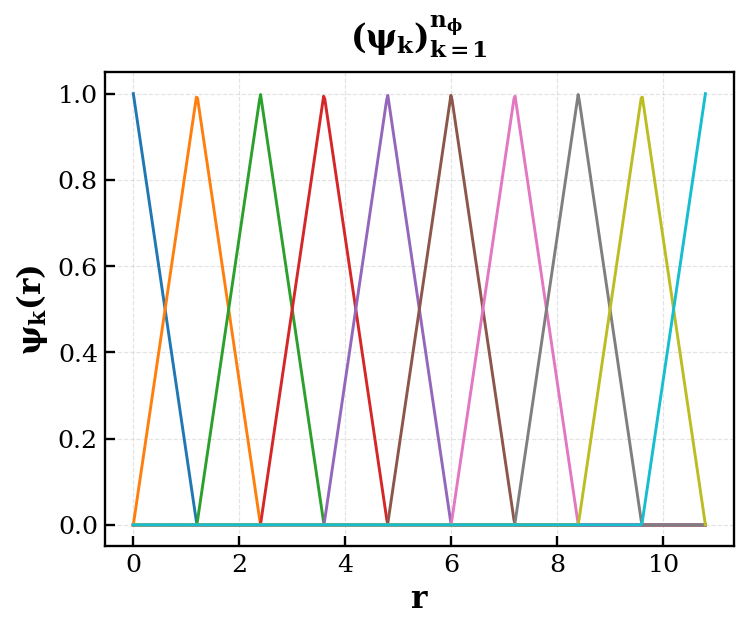

In [16]:
# Radial basis support plot

viz = DataSupportVisualizer()


fig_radial_basis = viz.plot_radial_basis_support(
    basis_bundle=basis_bundle,
)

fig_radial_basis


figure_dir = figure_repo.stage_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
)
figure_dir.mkdir(parents=True, exist_ok=True)

png_path = figure_dir / "radial_basis_support.png"
pdf_path = figure_dir / "radial_basis_support.pdf"

fig_radial_basis.savefig(png_path, dpi=300, bbox_inches="tight")
fig_radial_basis.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
./artifacts/spp/figures/step_2_2b/environment_basis_support.png
./artifacts/spp/figures/step_2_2b/environment_basis_support.pdf


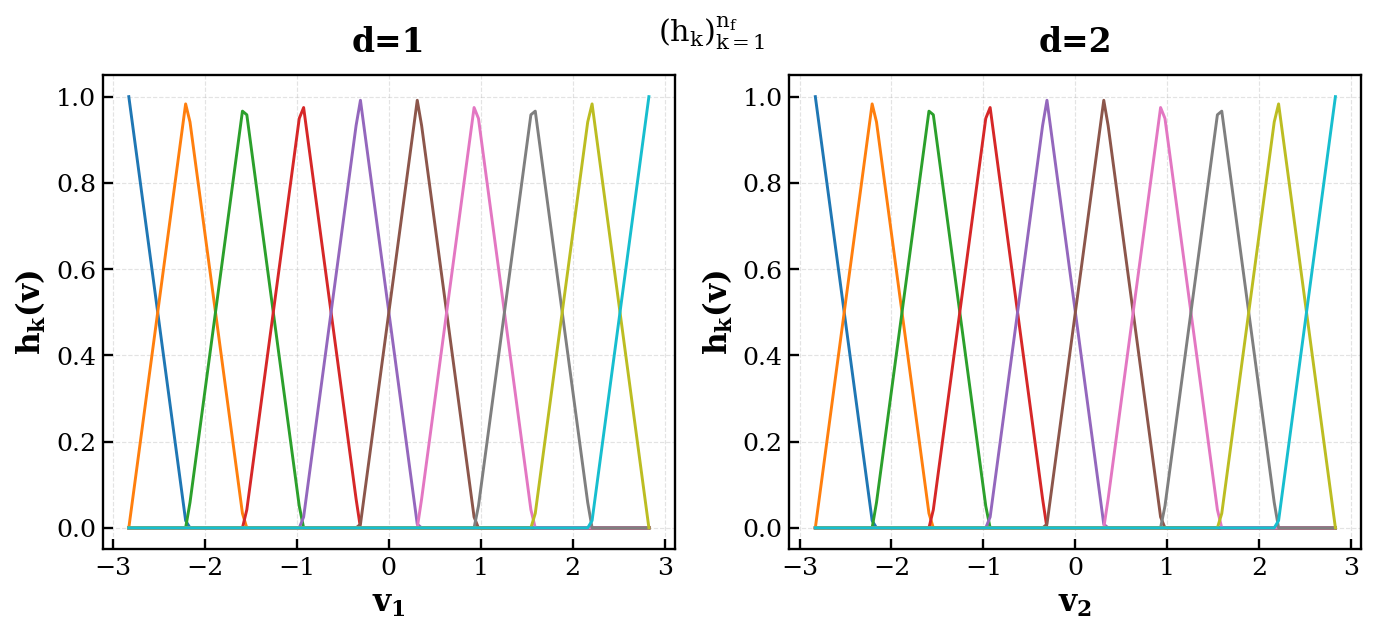

In [17]:
# Velocity basis support plot
fig_environment_basis = viz.plot_environment_basis_support(
    basis_bundle=basis_bundle,
    variable_label="x" if SYSTEM_ORDER == 1 else "v",
)

png_path = figure_dir / "environment_basis_support.png"
pdf_path = figure_dir / "environment_basis_support.pdf"

fig_environment_basis.savefig(png_path, dpi=300, bbox_inches="tight")
fig_environment_basis.savefig(pdf_path, bbox_inches="tight")

print("Saved:")
print(png_path)
print(pdf_path)

# Stage 4b: Learned function visualizations

reference distance density \(\rho_R(r)\), environment density \(\rho_Z(z)\)

where \(z=v\) for second-order systems and \(z=x\) for first-order systems.

In [18]:
FIGURE_STAGE = "step_4b"
FIT_CASE_NAME = TRAIN_FIT_DATASET_NAME

In [19]:
# true kernel, f for comparison from metadata
from ips_learning.systems.registry import (
    true_env_from_metadata,
    true_kernel_from_metadata)

true_phi = true_kernel_from_metadata(train_fit_dataset.metadata)
true_f = true_env_from_metadata(train_fit_dataset.metadata)

print("True SPP functions prepared.")

True SPP functions prepared.


In [20]:
from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
# loading fit repo
fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

fit_result = fit_repo.load_fit_result(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    fit_case_name=FIT_CASE_NAME,
)
learned_model = LearnedModelFactory().build_from_fit_result(
    fit_result=fit_result,
    N=int(fit_result.metadata["N"]),
    D=int(fit_result.metadata["D"]),
)

print("Learned model reconstructed.")
print("interaction_type:", learned_model.interaction_type)

Learned model reconstructed.
interaction_type: energy


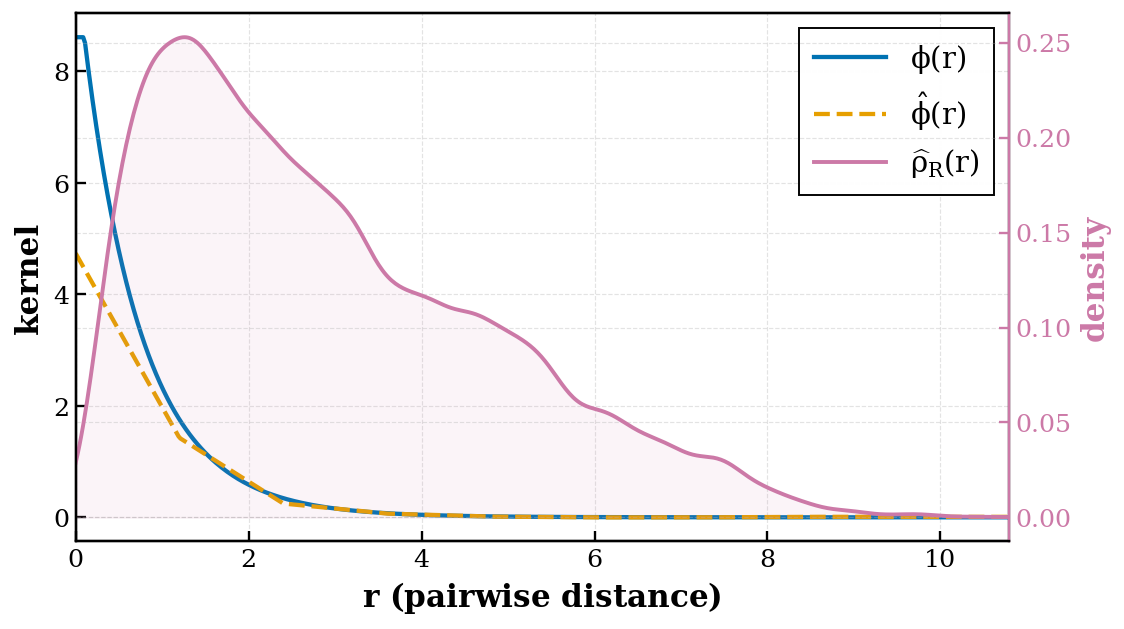

In [21]:
from ips_learning.visualization.learned_functions import LearnedFunctionVisualizer
viz = LearnedFunctionVisualizer()

fig_kernel = viz.plot_kernel_with_support(
    learned_model=learned_model,
    basis_bundle=basis_bundle,
    r_grid=r_grid,
    # reference_pdf=reference_pdf,
    train_density=train_density,
    true_kernel=true_phi,
    labels={
        "true_kernel_label": r"$\phi(r)$",
        "learned_kernel_label": r"$\hat{\phi}(r)$",
        "train_density_label": r"$\widehat{\rho}_R(r)$",
        "xlabel": r"$r$ (pairwise distance)",
        "y1label": "kernel",
        "y2label": "density",
        "legend_loc": "best",
        "legend_bbox_to_anchor": None,
    },
)

figure_repo.save(
    fig_kernel,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_kernel_phi",
)
fig_kernel

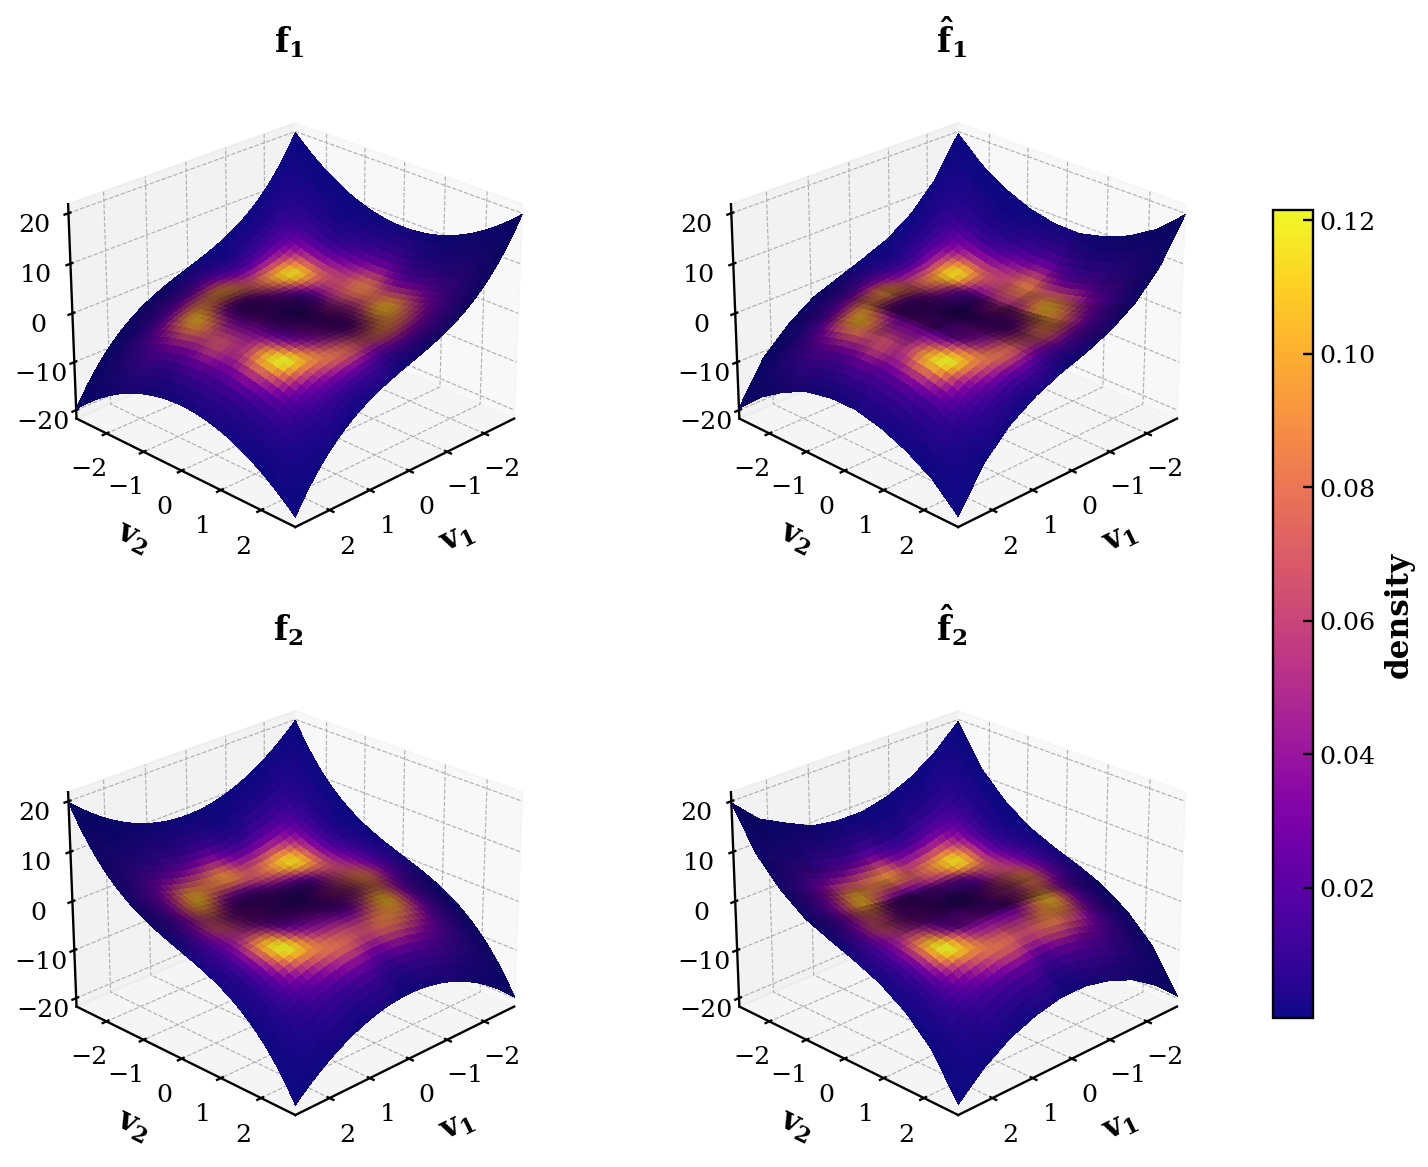

In [22]:
fig_f = viz.plot_environment_with_support(
    learned_model=learned_model,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=train_density_grid,
    true_env=true_f,
    environment_variable="x" if SYSTEM_ORDER == 1 else "v",
    labels={
        "x1_label": r"$v_1$",
        "x2_label": r"$v_2$",
        "true_comp1_label": r"$f_{1}$",
        "true_comp2_label": r"$f_{2}$",
        "learned_comp1_label": r"$\hat f_{1}$",
        "learned_comp2_label": r"$\hat f_{2}$",
        "colorbar_label": "density",
    },
)
figure_repo.save(
    fig_f,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_f",
)
fig_f


#change to data distribution instesd of true distribution

# Stage 4c: Algorithm comparison — learned functions

In [23]:
FIGURE_STAGE = "step_4c"
ALGORITHMS = ("nonparametric_f", "parametric_f")

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.visualization.algorithm_comparison import AlgorithmComparison

fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

FIT_RESULTS = {}
LEARNED_MODELS = {}

for algorithm in ALGORITHMS:
    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        fit_case_name=FIT_CASE_NAME,
    )

    learned_model = LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=int(fit_result.metadata["N"]),
        D=int(fit_result.metadata["D"]),
    )

    FIT_RESULTS[algorithm] = fit_result
    LEARNED_MODELS[algorithm] = learned_model

    print("Loaded:", algorithm, fit_result.theta.shape)

Loaded: nonparametric_f (210, 1)
Loaded: parametric_f (18, 1)


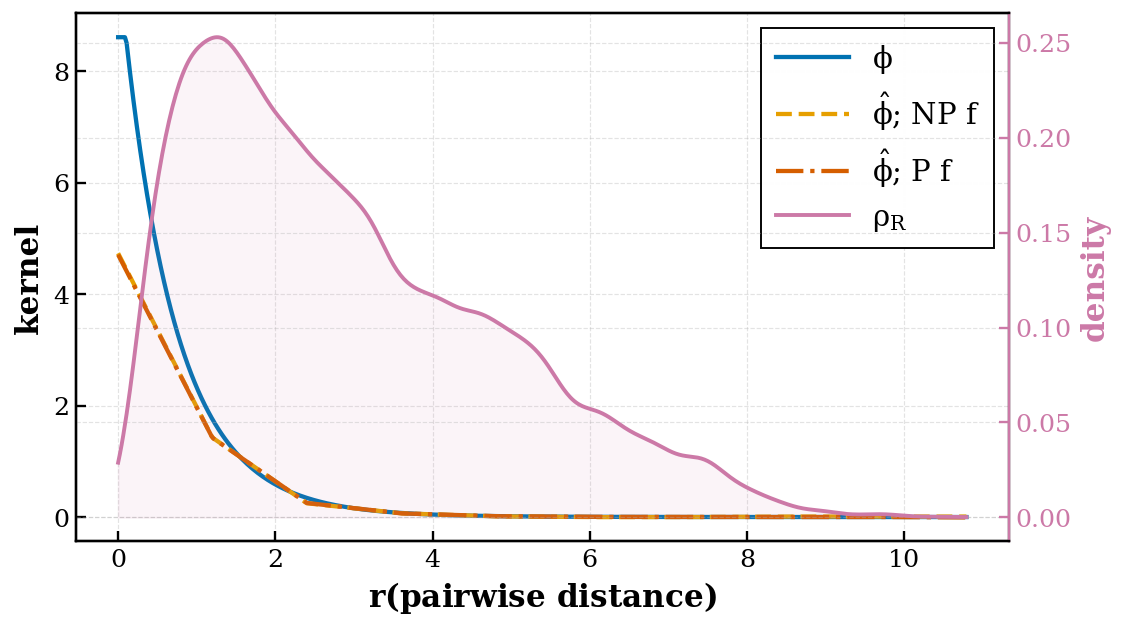

In [24]:
viz = AlgorithmComparison()

fig_kernel_compare = viz.plot_kernel_algorithm_comparison(
    r_grid=r_grid,
    true_kernel=true_phi,
    learned_models=LEARNED_MODELS,
    train_density=train_density,
    labels={
        "x_label": r"$r$(pairwise distance)",
        "y_label": "kernel",
        "y2_label": "density",
        "density_label": r"$\rho_R$",
        "true_label": r"$\phi$",
        "learned_labels": {
            "nonparametric_f": r"$\hat{\phi}$; NP $f$",
            "parametric_f": r"$\hat{\phi}$; P $f$",
        },
        "legend_loc": "best",
    },
)

figure_repo.save(
    fig_kernel_compare,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_kernel_phi_parametric_f_basis.png",
)
fig_kernel_compare

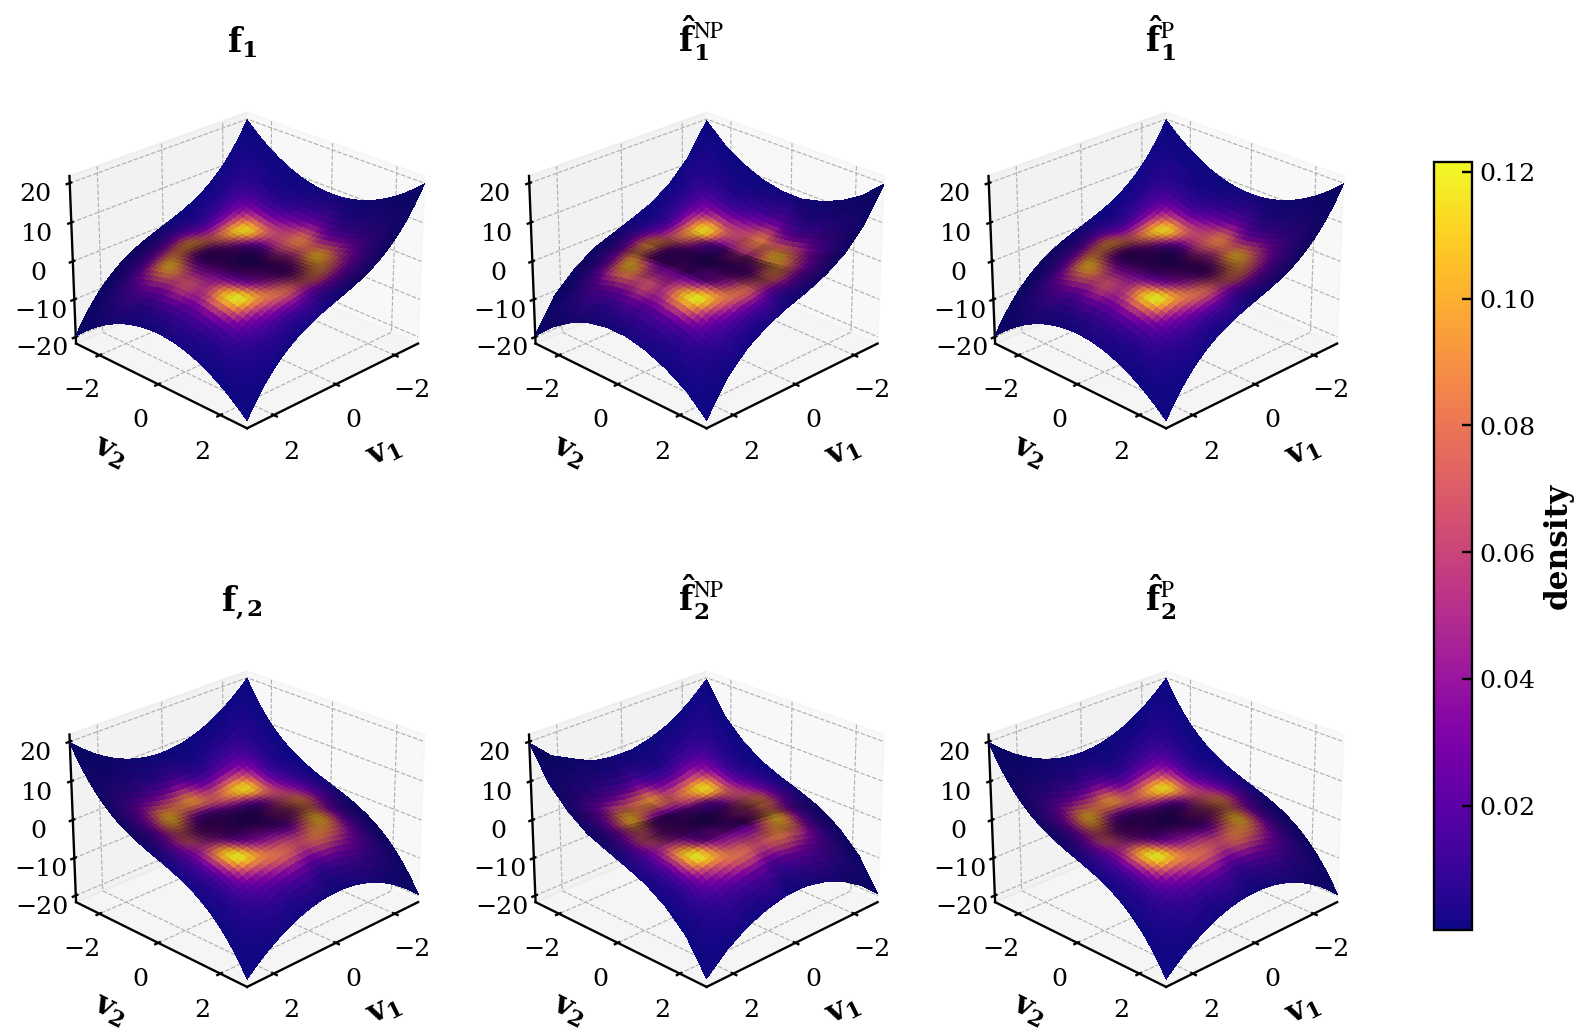

In [25]:
fig_f_compare = viz.plot_environment_surfaces_2d(
    learned_models=LEARNED_MODELS,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=train_density_grid,
    true_env=true_f,
    environment_variable="v",
    zlim_mode="joint",
    labels={
        "x1_label": r"$v_1$",
        "x2_label": r"$v_2$",
        "true_comp_labels": [
            r"$f_{1}$",
            r"$f_{,2}$",
        ],
        "learned_comp_labels": {
            "nonparametric_f": [
                r"$\hat f_{1}^{\mathrm{NP}}$",
                r"$\hat f_{2}^{\mathrm{NP}}$",
            ],
            "parametric_f": [
                r"$\hat f_{1}^{\mathrm{P}}$",
                r"$\hat f_{2}^{\mathrm{P}}$",
            ],
        },
        "colorbar_label": "density",#r"$\rho_v$",
        "show_zlabel": False,
    },
)

figure_repo.save(
    fig_f_compare,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_f_parametric_f_basis",
)
fig_f_compare

# Stage 5b: Rollout visualizations — true vs learned trajectories

In [26]:
FIGURE_STAGE = "step_5b"
FIT_CASE_NAME = TRAIN_FIT_DATASET_NAME
ANIMATION_END_TIME = 5.0
ANIMATION_N = 40

ALGORITHMS = ("nonparametric_f", "parametric_f")

FIT_RECON_ROLLOUT_NAME = f"{FIT_CASE_NAME}_train_fit_reconstruction"
TRAIN_FULL_ROLLOUT_NAME = f"{FIT_CASE_NAME}_train_full_prediction"
TEST_ROLLOUT_NAME = f"{FIT_CASE_NAME}_test_prediction"
TEST_ANIMATION_ROLLOUT_NAME = (
    f"{FIT_CASE_NAME}_test_animation_T{ANIMATION_END_TIME:g}_N{ANIMATION_N}"
)

TRAIN_SPLIT = "train"
TEST_SPLIT = "test"

TRAIN_DATASET_NAME = "dataset_train_trial_001"
TEST_DATASET_NAME = "dataset_test"
TEST_ANIMATION_DATASET_NAME = f"{TEST_DATASET_NAME}_animation_T{ANIMATION_END_TIME:g}"

FIT_END_TIME = 0.5


In [27]:
from ips_learning.rollout.repository import RolloutRepository

rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")
ROLLOUT_ARTIFACTS = {}

for algorithm in ALGORITHMS:
    train_full_artifact = rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        case_name=FIT_CASE_NAME,
        scenario="train_full_prediction",
        rollout_name=TRAIN_FULL_ROLLOUT_NAME,
    )

    test_artifact = rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=algorithm,
        case_name=FIT_CASE_NAME,
        scenario="test_prediction",
        rollout_name=TEST_ROLLOUT_NAME,
    )

    test_animation_artifact = rollout_repo.load_case(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    algorithm=algorithm,
    case_name=FIT_CASE_NAME,
    scenario="test_animation_prediction",
    rollout_name=TEST_ANIMATION_ROLLOUT_NAME,
)

    ROLLOUT_ARTIFACTS[algorithm] = {
        "train_full_prediction": train_full_artifact,
        "test_prediction": test_artifact,
        "test_animation_prediction": test_animation_artifact,
    }

    print("Loaded rollout artifacts:", algorithm)
    print("train full:", train_full_artifact.X_hat.shape)
    print("test:", test_artifact.X_hat.shape)

Loaded rollout artifacts: nonparametric_f
train full: (50, 201, 10, 2)
test: (10, 201, 10, 2)
Loaded rollout artifacts: parametric_f
train full: (50, 201, 10, 2)
test: (10, 201, 10, 2)


In [28]:
# true datasets

train_full_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

test_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

test_animation_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_ANIMATION_DATASET_NAME,
)


In [29]:
# Helper to extract one trajectory
def extract_single_trajectory(dataset, artifact, m: int = 0):
    """
    Convert saved layout:
        dataset.X[m]      : (L, N, D)
        artifact.X_hat[m] : (L, N, D)

    to visualization layout:
        X_true : (N, D, L)
        X_hat  : (N, D, L)

    V_true and V_hat are None for first-order systems.
    """
    t = dataset.t

    X_true = np.transpose(dataset.X[m], (1, 2, 0))
    X_hat = np.transpose(artifact.X_hat[m], (1, 2, 0))

    if dataset.V is None:
        V_true = None
    else:
        V_true = np.transpose(dataset.V[m], (1, 2, 0))

    if artifact.V_hat is None:
        V_hat = None
    else:
        V_hat = np.transpose(artifact.V_hat[m], (1, 2, 0))

    return t, X_true, V_true, X_hat, V_hat

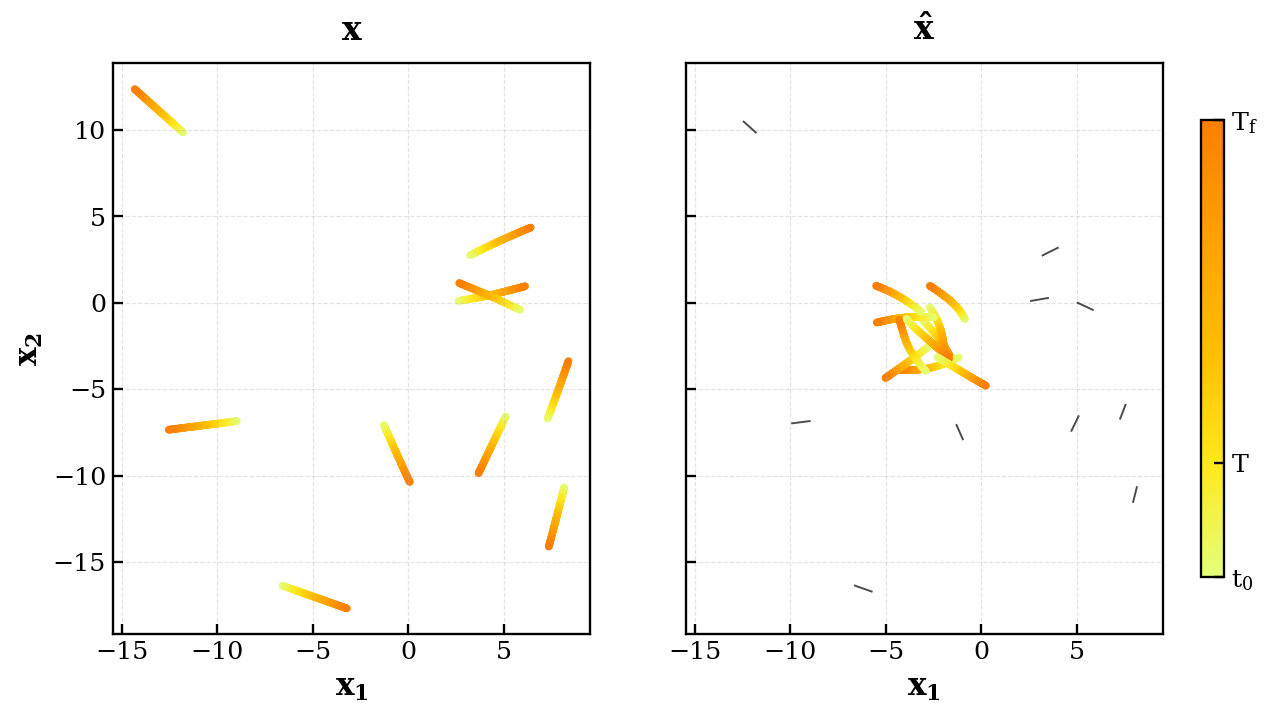

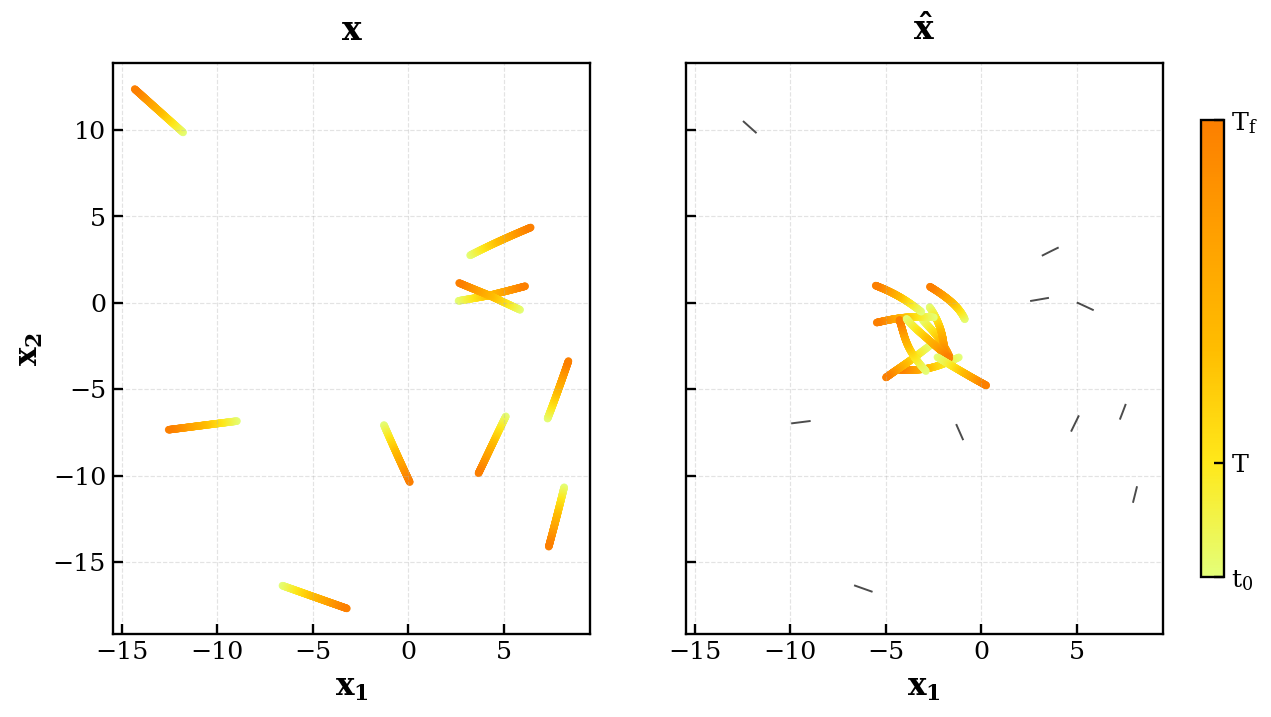

In [30]:
from ips_learning.visualization.trajectories import TrajectoryVisualizer

viz = TrajectoryVisualizer()

for algorithm in ALGORITHMS:
    train_full_artifact = ROLLOUT_ARTIFACTS[algorithm]["train_full_prediction"]

    t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
        train_full_dataset,
        train_full_artifact,
        m=0,
    )

    fig_phase_train = viz.plot_true_vs_learned_phase_portrait(
        t=t,
        X_true=X_true,
        X_hat=X_hat,
        train_fit_end_pt=FIT_END_TIME,
        train_fit_mark=True,
        title_true= r"$x$",#r"$x_0 \in M_{\mathrm{train}}: x$",
        title_hat= r"$\hat{x}$",#r"$x_0 \in M_{\mathrm{train}}: \hat{x}$",
    )

    figure_repo.save(
        fig_phase_train,
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"{algorithm}_train_full_phase_portrait",
        close=False,
    )

    # fig_coord_train = viz.plot_true_vs_learned_coordinate(
    #     t_true=t,
    #     X_true=X_true,
    #     t_hat=train_full_artifact.t,
    #     X_hat=X_hat,
    #     component=0,
    #     train_fit_end_pt=FIT_END_TIME,
    #     highlight_agent=0,
    #     title=rf"Levi: $x_0 \in M_{{\mathrm{{train}}}},\ t \in [t_0,T_f]$ ({algorithm})",
    # )

    # figure_repo.save(
    #     fig_coord_train,
    #     system_name=SYSTEM_NAME,
    #     stage_name=FIGURE_STAGE,
    #     file_name=f"{algorithm}_train_full_coordinate",
    #     close=False,
    # )

PosixPath('./artifacts/spp/figures/step_5b/train_full_phase_portrait_true_parametric_nonparametric.png')

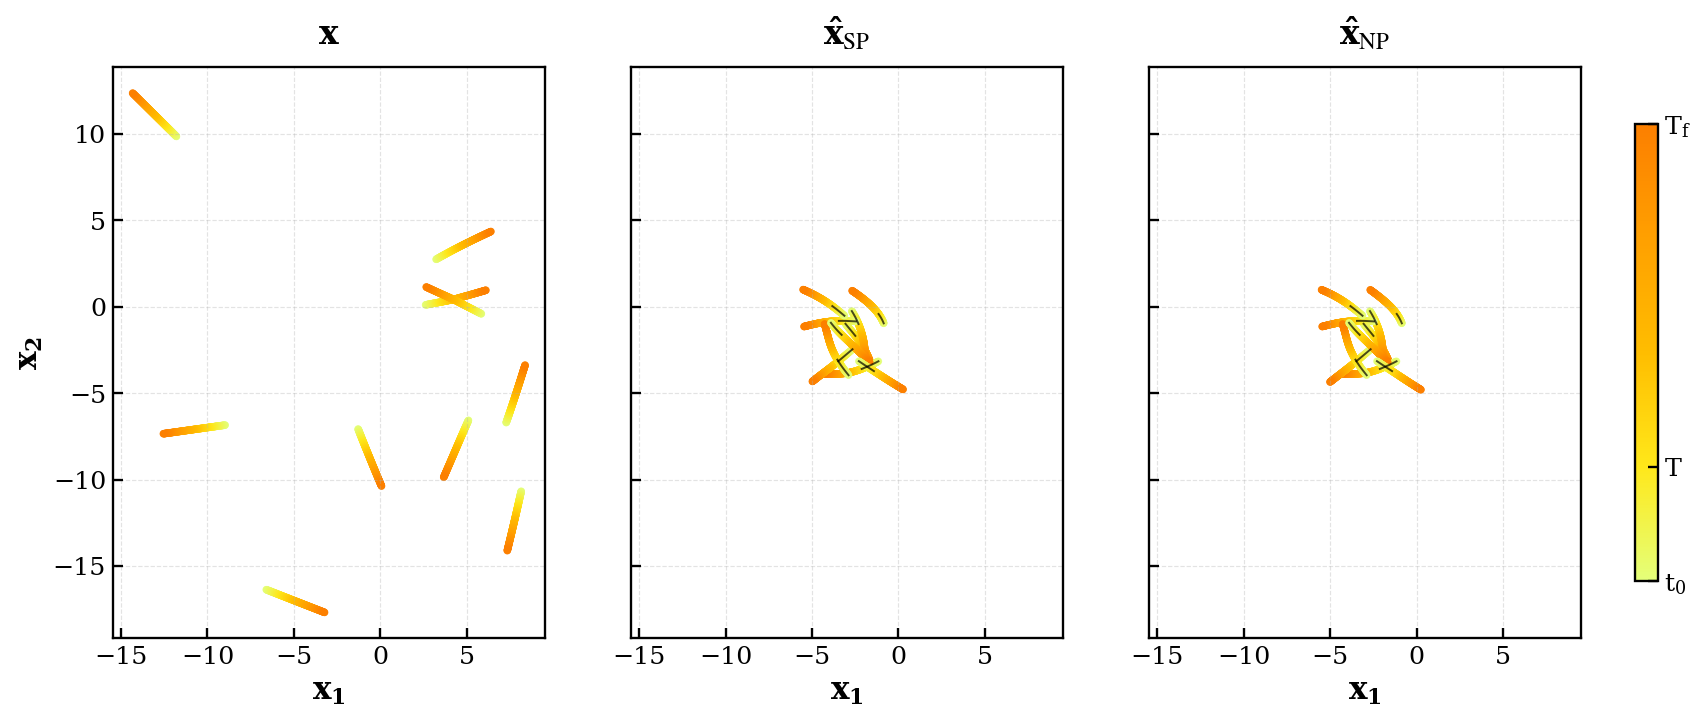

In [31]:
train_full_parametric = ROLLOUT_ARTIFACTS["parametric_f"]["train_full_prediction"]
train_full_nonparametric = ROLLOUT_ARTIFACTS["nonparametric_f"]["train_full_prediction"]

t, X_true, V_true, X_parametric, V_parametric = extract_single_trajectory(
    train_full_dataset,
    train_full_parametric,
    m=0,
)

_, _, _, X_nonparametric, V_nonparametric = extract_single_trajectory(
    train_full_dataset,
    train_full_nonparametric,
    m=0,
)

fig_phase_train = viz.plot_true_parametric_nonparametric_phase_portrait(
    t=t,
    X_true=X_true,
    X_parametric=X_parametric,
    X_nonparametric=X_nonparametric,
    train_fit_end_pt=FIT_END_TIME,
    train_fit_mark=True,
    title_true=r"$x$",
    title_parametric=r"$ \hat{x}_{\mathrm{SP}}$",
    title_nonparametric=r"$ \hat{x}_{\mathrm{NP}}$",
)

figure_repo.save(
    fig_phase_train,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="train_full_phase_portrait_true_parametric_nonparametric",
    close=False,
)

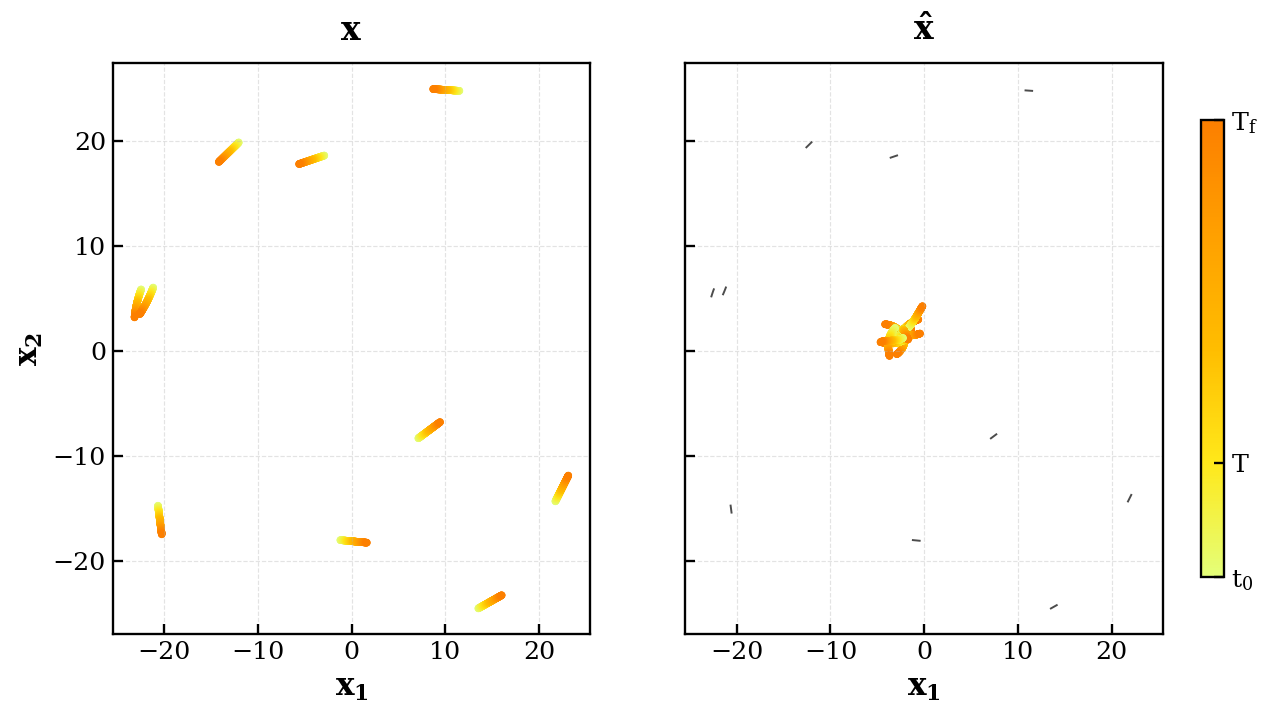

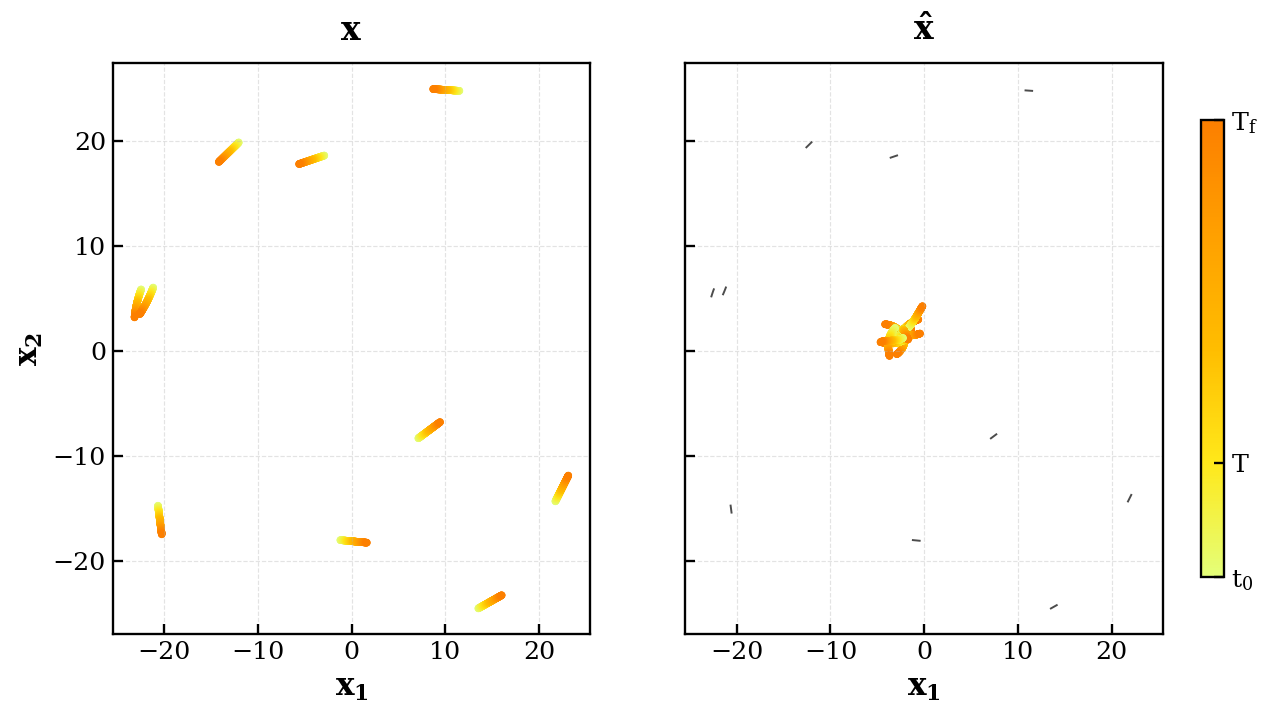

In [32]:
# unseen test prediction phase portrait
for algorithm in ALGORITHMS:
    train_full_artifact = ROLLOUT_ARTIFACTS[algorithm]["test_prediction"]

    t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
        test_dataset,
        test_artifact,
        m=0,
    )

    fig_phase_train = viz.plot_true_vs_learned_phase_portrait(
        t=t,
        X_true=X_true,
        X_hat=X_hat,
        train_fit_end_pt=FIT_END_TIME,
        train_fit_mark=True,
        title_true= r"$x$",#r"$x_0 \in M_{\mathrm{test}}: x$",
        title_hat= r"$\hat{x}$",#r"$x_0 \in M_{\mathrm{test}}: \hat{x}$",
    )

    figure_repo.save(
        fig_phase_train,
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"{algorithm}_test_phase_portrait",
        close=False,
    )

    # fig_coord_train = viz.plot_true_vs_learned_coordinate(
    #     t_true=t,
    #     X_true=X_true,
    #     t_hat=train_full_artifact.t,
    #     X_hat=X_hat,
    #     component=0,
    #     train_fit_end_pt=FIT_END_TIME,
    #     highlight_agent=0,
    #     title=rf"Levi: $x_0 \in M_{{\mathrm{{test}}}},\ t \in [t_0,T_f]$ ({algorithm})",
    # )

    # figure_repo.save(
    #     fig_coord_train,
    #     system_name=SYSTEM_NAME,
    #     stage_name=FIGURE_STAGE,
    #     file_name=f"{algorithm}_test_full_coordinate",
    #     close=False,
    # )

PosixPath('./artifacts/spp/figures/step_5b/test_full_phase_portrait_true_parametric_nonparametric.png')

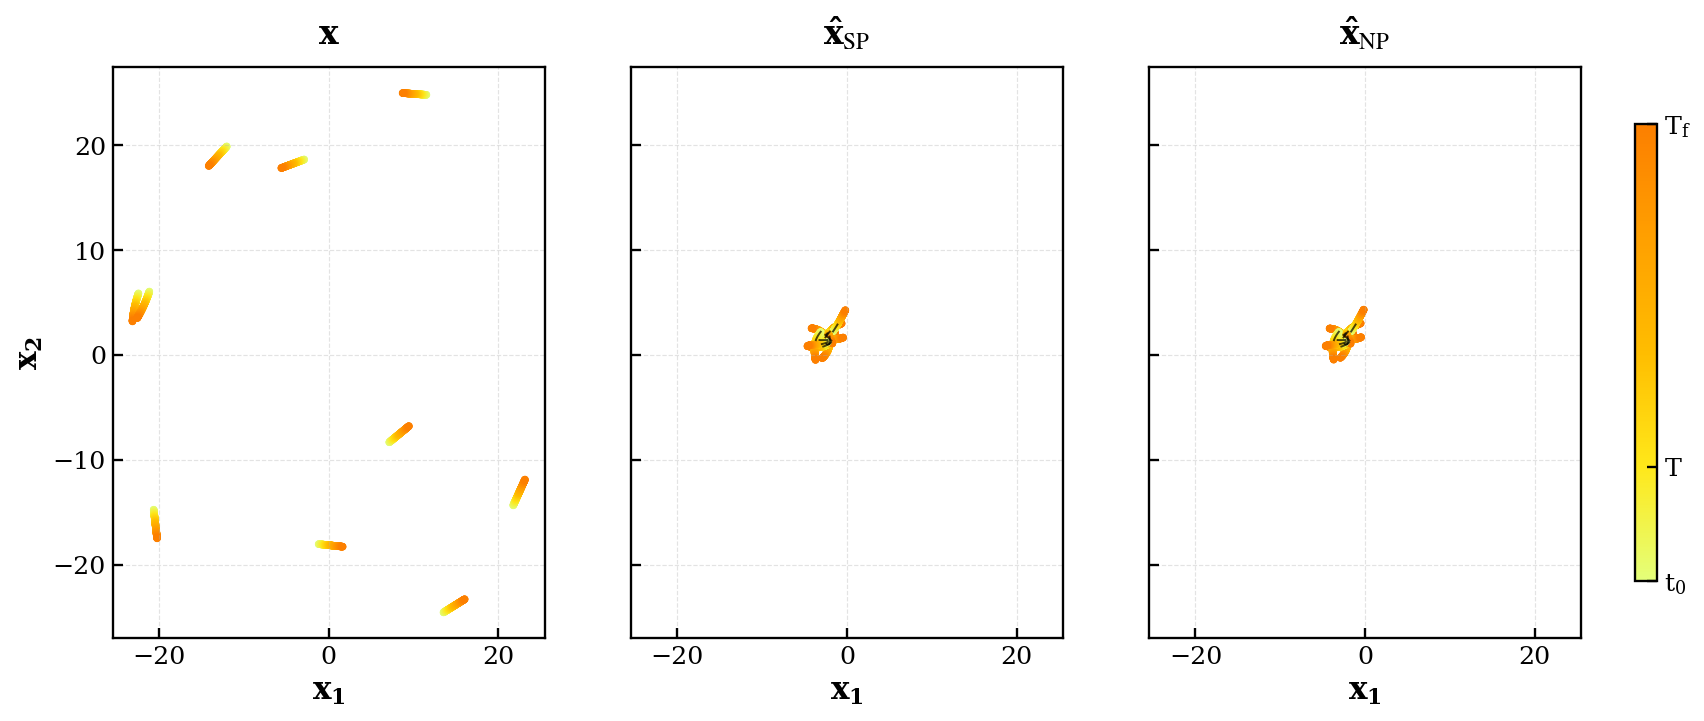

In [33]:
test_full_parametric = ROLLOUT_ARTIFACTS["parametric_f"]["test_prediction"]
test_full_nonparametric = ROLLOUT_ARTIFACTS["nonparametric_f"]["test_prediction"]

t, X_true, V_true, X_parametric, V_parametric = extract_single_trajectory(
    test_dataset,
    test_full_parametric,
    m=0,
)

_, _, _, X_nonparametric, V_nonparametric = extract_single_trajectory(
    test_dataset,
    test_full_nonparametric,
    m=0,
)

fig_phase_train = viz.plot_true_parametric_nonparametric_phase_portrait(
    t=t,
    X_true=X_true,
    X_parametric=X_parametric,
    X_nonparametric=X_nonparametric,
    train_fit_end_pt=FIT_END_TIME,
    train_fit_mark=True,
    title_true=r"$x$",
    title_parametric=r"$ \hat{x}_{\mathrm{SP}}$",
    title_nonparametric=r"$ \hat{x}_{\mathrm{NP}}$",
)

figure_repo.save(
    fig_phase_train,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="test_full_phase_portrait_true_parametric_nonparametric",
    close=False,
)

PosixPath('./artifacts/spp/figures/step_5b/test_ani_full_phase_portrait_true_parametric_nonparametric.png')

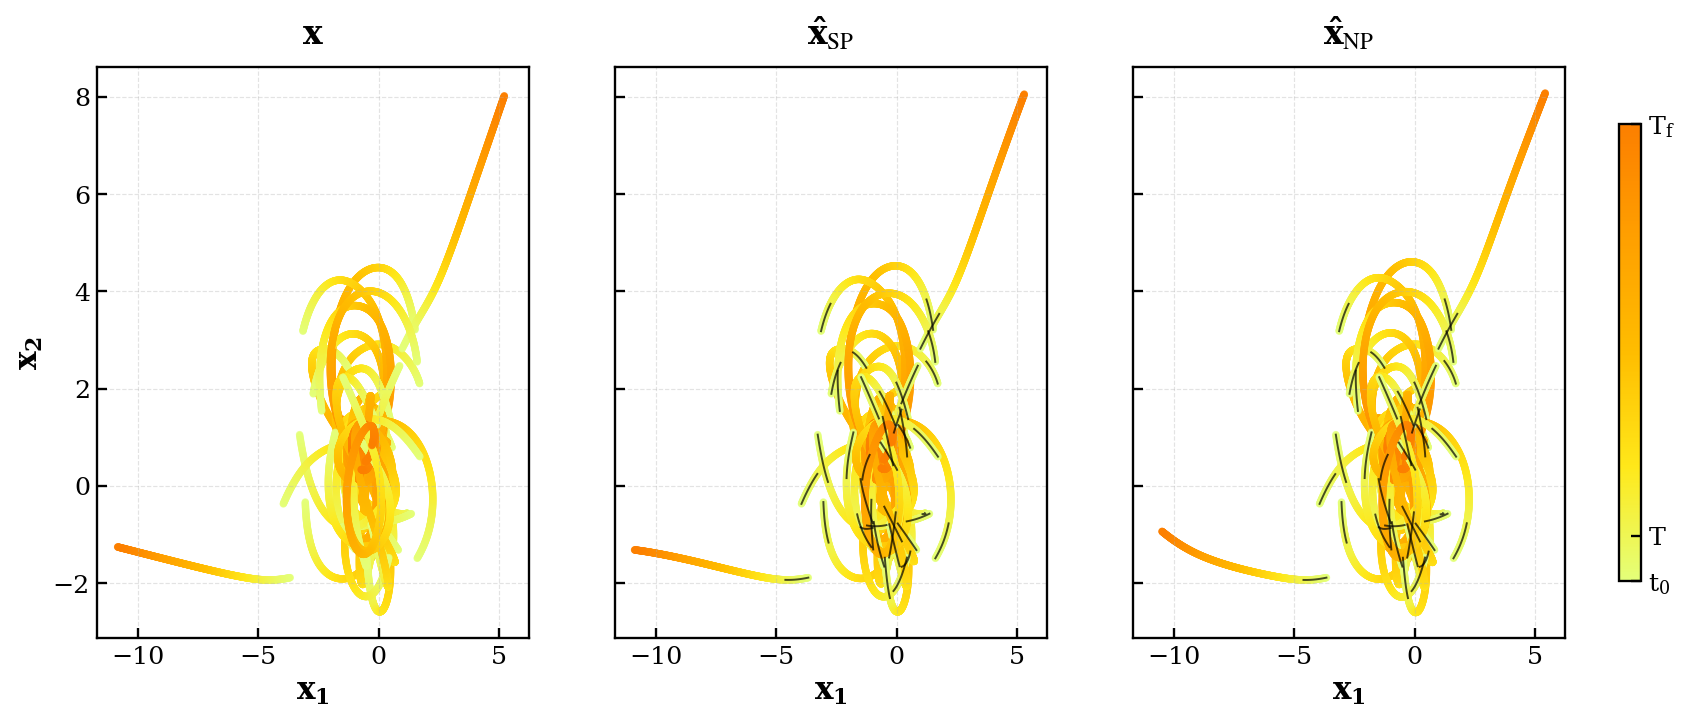

In [34]:
test_animation_full_parametric = ROLLOUT_ARTIFACTS["parametric_f"]["test_animation_prediction"]
test_animation_full_nonparametric = ROLLOUT_ARTIFACTS["nonparametric_f"]["test_animation_prediction"]

t, X_true, V_true, X_parametric, V_parametric = extract_single_trajectory(
    test_animation_dataset,
    test_animation_full_parametric,
    m=0,
)

_, _, _, X_nonparametric, V_nonparametric = extract_single_trajectory(
    test_animation_dataset,
    test_animation_full_nonparametric,
    m=0,
)

fig_phase_train = viz.plot_true_parametric_nonparametric_phase_portrait(
    t=t,
    X_true=X_true,
    X_parametric=X_parametric,
    X_nonparametric=X_nonparametric,
    train_fit_end_pt=FIT_END_TIME,
    train_fit_mark=True,
    title_true=r"$x$",
    title_parametric=r"$ \hat{x}_{\mathrm{SP}}$",
    title_nonparametric=r"$ \hat{x}_{\mathrm{NP}}$",
)

figure_repo.save(
    fig_phase_train,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="test_ani_full_phase_portrait_true_parametric_nonparametric",
    close=False,
)

Animation frames: 500 (original time points: 501)
Saved GIF: ./artifacts/spp/figures/step_5b/test_true_vs_learned_animation_nonparametric.gif


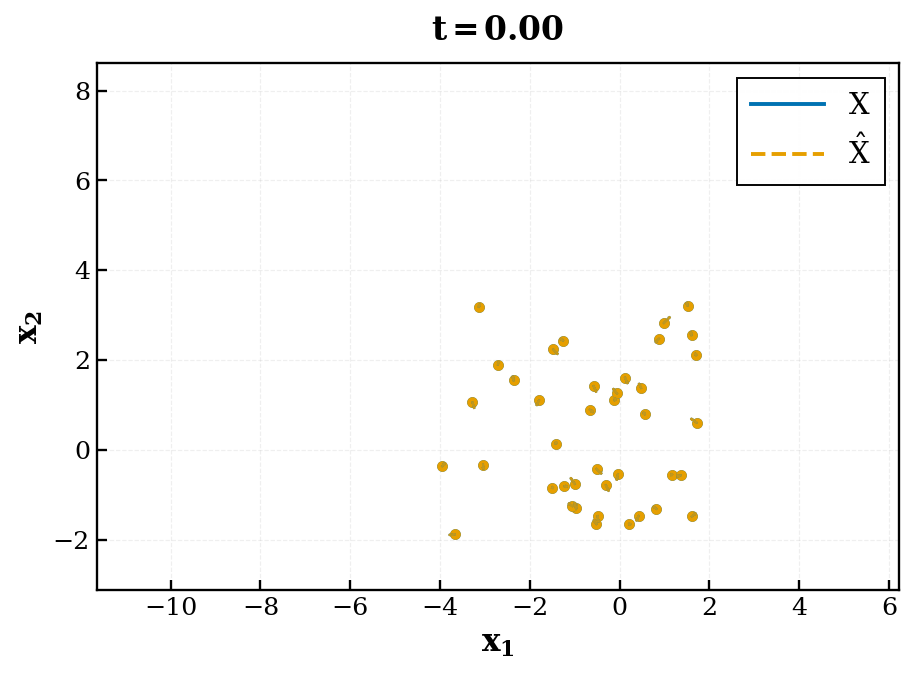

In [37]:
# animation
t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
    test_animation_dataset,
    test_animation_full_nonparametric,
    m=0,
)

fig_anim, ani = viz.animate_true_vs_learned(
    t=t,
    X_true=X_true,
    V_true=V_true,
    X_hat=X_hat,
    V_hat=V_hat,
    interval=1000 * (t[1] - t[0]),
)

gif_path = figure_repo.save_gif(
    ani,
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    stage_name=FIGURE_STAGE,
    file_name="test_true_vs_learned_animation_nonparametric",
    fps=100,
)

print("Saved GIF:", gif_path)

In [36]:
# # animation
# t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
#     test_animation_dataset,
#     test_animation_full_parametric,
#     m=0,
# )

# fig_anim, ani = viz.animate_true_vs_learned(
#     t=t,
#     X_true=X_true,
#     V_true=V_true,
#     X_hat=X_hat,
#     V_hat=V_hat,
#     interval=60,
# )

# gif_path = figure_repo.save_gif(
#     ani,
#     system_name=SYSTEM_NAME,
#     stage_name=FIGURE_STAGE,
#     file_name="test_true_vs_learned_animation_parametric",
#     fps=30,
# )

# print("Saved GIF:", gif_path)
